<a href="https://colab.research.google.com/github/tphan356/household-object-classification/blob/main/code/household_object_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Household Object Classification

A deep learning project focused on classifying common household objects using computer vision, with potential applications in intelligent home robotics.

## Set up

Install the required libraries for downloading the dataset and building the image classification model.

In [ ]:
!pip install -q kagglehub

### Import library

Import the libraries needed for data exploration, duplicate detection, image processing, model training, and evaluation.

In [ ]:
import fastai
import kagglehub
import numpy as np
import pandas as pd
import torch
import hashlib

from collections import defaultdict
from pathlib import Path
from fastai.vision.all import *
from fastcore.all import *
from fastdownload import download_url

### Check instrallation

Verify the Fastai and PyTorch versions and check whether a GPU is available for model training.

In [ ]:
print("Fastai version:", fastai.__version__)
print("PyTorch version:", torch.__version__)
print("GPU available", torch.cuda.is_available())

Fastai version: 2.8.12
PyTorch version: 2.11.0+cu130
GPU available True


## Domain Problem

Image classification is a computer vision task that involves predicting the category of an image.

Unlike binary classification, which distinguishes between two categories, this project focuses on multi-class classification across five furniture categories: bed, chair, sofa, swivel chair, and table.

The main challenge is that furniture can vary significantly in shape, size, and appearance. Some categories, particularly chairs and swivel chairs, also share similar visual features.

Research Question: Can a pretrained ResNet34 model accurately classify five different furniture categories?

My long-term motivation comes from intelligent home robotics, but this project focuses specifically on image classification as the first step.

## Analytic Approach

I will use transfer learning with a pretrained ResNet34 model to classify furniture images.

The model will learn to distinguish five categories using labeled images. I will evaluate its performance using validation accuracy, error rate, a confusion matrix, and an analysis of incorrect predictions.

I will also test the trained model on external images to explore how it performs on photographs outside the Kaggle dataset.

## Household Object Classifier

### Dataset Selection

Initially, I selected the [Furniture Image Dataset](https://www.kaggle.com/datasets/udaysankarmukherjee/furniture-image-dataset) from Kaggle, which contained approximately 15,000 image files. However, during data exploration, I discovered that only around 600 images were unique.

This raised concerns about duplicate images potentially appearing in both the training and validation sets, which could lead to misleading evaluation results.

Therefore, I switched to the [Furniture Detector dataset](https://www.kaggle.com/datasets/akkithetechie/furniture-detector), which contains five furniture categories:

1. Bed
2. Chair
3. Sofa
4. Swivel Chair
5. Table

I will examine the dataset, remove duplicate images and conflicting labels, and prepare the cleaned data for model training.




### Download the dataset

Download the Furniture Detector dataset from Kaggle using kagglehub.

In [ ]:
path = Path(kagglehub.dataset_download("akkithetechie/furniture-detector"))

print("Dataset location:", path)

100%|██████████| 232M/232M [00:02<00:00, 120MB/s]

Extracting files...


Dataset location: /root/.cache/kagglehub/datasets/akkithetechie/furniture-detector/versions/1


### Examine the downloaded files

Examine the downloaded directory structure to locate the furniture images and avoid loading duplicate dataset directories.

In [ ]:
for item in sorted(path.iterdir()):
    print(item.name)

furniture-images
img


### Get all image files

Load the images from the selected furniture-images directory and examine their file paths.

In [ ]:
image_root = path / "furniture-images"

if not image_root.exists():
    image_root = path

file_names = get_image_files(image_root)

print("Total image files:", len(file_names))
print("Sample image paths:")

for file in file_names[:5]:
    print(file.relative_to(path))

Total image files: 4447
Sample image paths:
furniture-images/img/train/sofa/00000758.jpg
furniture-images/img/train/sofa/00000828.jpg
furniture-images/img/train/sofa/00000724.jpg
furniture-images/img/train/sofa/00000707.jpg
furniture-images/img/train/sofa/00000045.jpg


### Define the labeling function

Unlike the cats-versus-dogs example, where labels can be identified from filenames, this dataset organizes images into category folders.

I created a labeling function that identifies each image's category based on its parent folder name.

I then counted the images in each category to examine the dataset distribution.

In [ ]:
class_names = {"bed", "chair", "sofa", "swivelchair", "table"}

def label_function(file_name):
    for folder in Path(file_name).parents:
        name = ''.join(c for c in folder.name.lower() if c.isalpha())

        if name in class_names:
            return name

    raise ValueError(f"No category found for {file_name}")

In [ ]:
labeled_files = []

for file in file_names:
    try:
        label_function(file)
        labeled_files.append(file)
    except ValueError:
        pass

class_counts = Counter(label_function(f) for f in labeled_files)

for category, count in sorted(class_counts.items()):
    print(f"{category}: {count} images")

print("Total labeled images:", len(labeled_files))
print("Unlabeled images skipped:", len(file_names) - len(labeled_files))

assert set(class_counts) == class_names, "Check the dataset folder structure."

bed: 1000 images
chair: 1000 images
sofa: 1000 images
swivelchair: 1000 images
table: 447 images
Total labeled images: 4447
Unlabeled images skipped: 0


### Remove dublicated image

Since my previous dataset contained a large number of duplicates, I wanted to check the new dataset before training.

I used SHA256 hashing to identify files with identical contents. I also excluded images with conflicting labels.

In [ ]:
def image_hash(file):
    with open(file, 'rb') as f:
        return hashlib.sha256(f.read()).hexdigest()

hash_groups = defaultdict(list)

for file in file_names:
    hash_groups[image_hash(file)].append(file)

unique_files = [
    files[0] for files in hash_groups.values()
    if len({label_function(f) for f in files}) == 1
]

print("Original images:", len(file_names))
print("Clean images:", len(unique_files))

Original images: 4447
Clean images: 4444


The dataset initially contained 4,447 images across five furniture categories. After removing exact duplicates and images with conflicting labels, I obtained **4,444 images**. The dataset is somewhat imbalanced, with fewer table images than the other categories.

### Display multiple sample images

Display one sample image from each furniture category to examine differences in shape, appearance, and design.

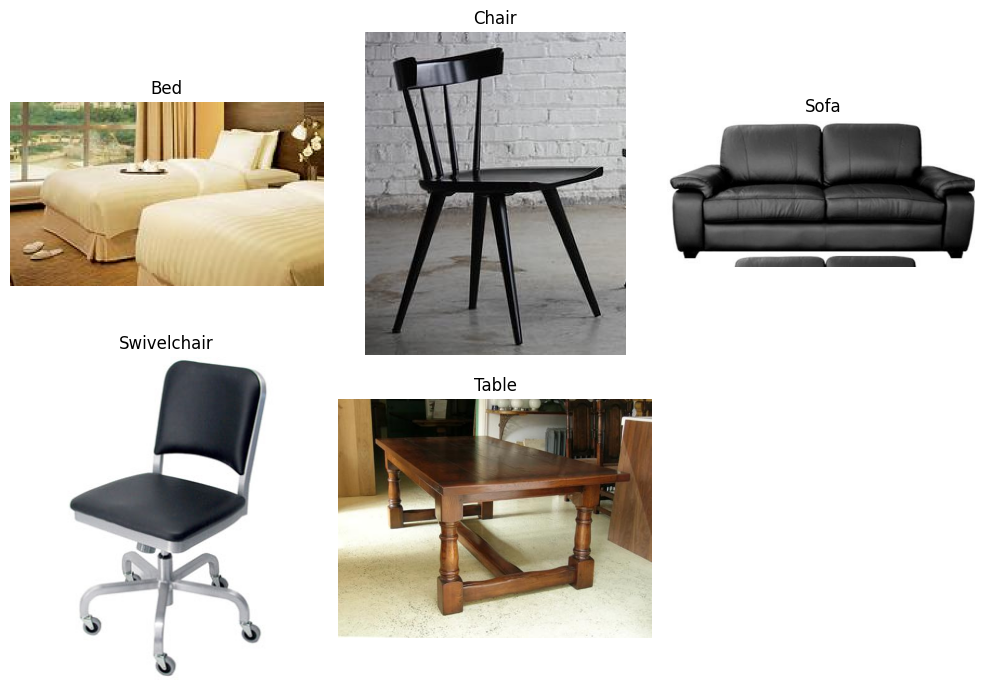

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(10, 7))

for ax, category in zip(axes.flat, sorted(class_names)):
    images = [f for f in labeled_files if label_function(f) == category]

    sample = random.choice(images)

    ax.imshow(PILImage.create(sample))
    ax.set_title(category.capitalize())
    ax.axis('off')

for ax in axes.flat[5:]:
    ax.axis('off')

plt.tight_layout()
plt.show()

## Data Processing

The images are organized into five furniture categories, so I can use their folder names as labels.

I will use Fastai's DataBlock to prepare the images and labels for model training.

Since the model requires a consistent image size, I will first resize the images to 460 × 460 pixels and then apply data augmentation to produce 224 × 224 images.

Data augmentation introduces variations during training, helping the model learn from different visual appearances.

## Set up DataBlock

Create a DataBlock that defines the image inputs, category labels, training-validation split, and image transformations.

In [ ]:
dblock = DataBlock(
    blocks = (ImageBlock, CategoryBlock),
    get_items = lambda p: unique_files,
    get_y = label_function,
    splitter = RandomSplitter(seed=42),                       # Split images into 80% training and 20% validation
    item_tfms = Resize(460),                                  # Resize each imgage to 460x460 before batching
    batch_tfms = aug_transforms(size = 224, min_scale = 0.75) # Apply data augmentation and resize images to 224x224
)

### Load the data

Create the Fastai data loaders using the cleaned image files.

In [ ]:
dls = dblock.dataloaders(image_root)

## Exploratory data analysis

Display a batch of transformed images to verify that the images and labels are loaded correctly.

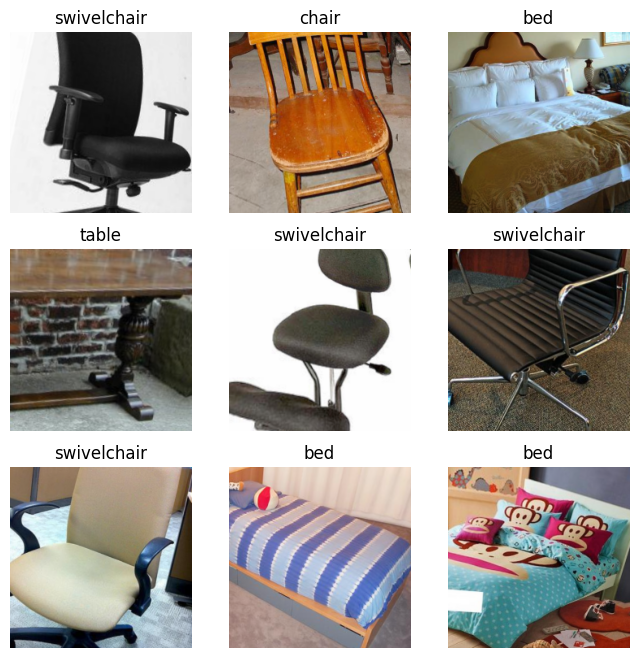

In [ ]:
dls.show_batch(max_n = 9, figsize=(8,8))

### Verify dataset

In [ ]:
print("Categories:", dls.vocab)
print("Training images:", len(dls.train_ds))
print("Validation images:", len(dls.valid_ds))

Categories: ['bed', 'chair', 'sofa', 'swivelchair', 'table']
Training images: 3556
Validation images: 888


## Modeling — Fine-Tuning

I will use a pretrained ResNet34 convolutional neural network to classify the five furniture categories. Instead of training a model from scratch, I will use transfer learning to adapt visual features previously learned from ImageNet to my dataset.

I will fine-tune the model using Fastai and evaluate its performance on the validation dataset.

### Create the neural network

Create a ResNet34 classifier using Fastai's vision_learner function, with error_rate as the evaluation metric.

In [ ]:
learn = vision_learner(dls, resnet34, metrics = error_rate)

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 168MB/s]


### Fine-tune the model

Fine-tune the pretrained model using fine_tune(1).

In [ ]:
learn.fine_tune(1)

epoch,train_loss,valid_loss,error_rate,time
0,0.801645,0.187086,0.059685,00:35


epoch,train_loss,valid_loss,error_rate,time
0,0.196667,0.120373,0.036036,00:37


In [ ]:
valid_loss, error = learn.validate()

accuracy = 1 - error

print(f"Validation Accuracy: {accuracy:.2%}")
print(f"Validation Error Rate: {error:.2%}")

Validation Accuracy: 96.40%
Validation Error Rate: 3.60%


### Model Performance

After fine-tuning, the ResNet34 model achieved 96.40% validation accuracy, with an error rate of 3.60%.

The training loss decreased from 0.801645 to 0.196667, while the validation loss decreased from 0.187086 to 0.120373.

These results suggest that the model learned to classify the five furniture categories effectively. Both training and validation losses decreased after fine-tuning.

## Model Evaluation

I will use a confusion matrix to examine the model's classification performance across the five furniture categories.

The confusion matrix shows how many images were correctly classified and which categories were confused with one another.

In [ ]:
interp = ClassificationInterpretation.from_learner(learn)

### Plot the Confusion Matrix

Plot the confusion matrix to compare the actual furniture categories with the model's predictions.

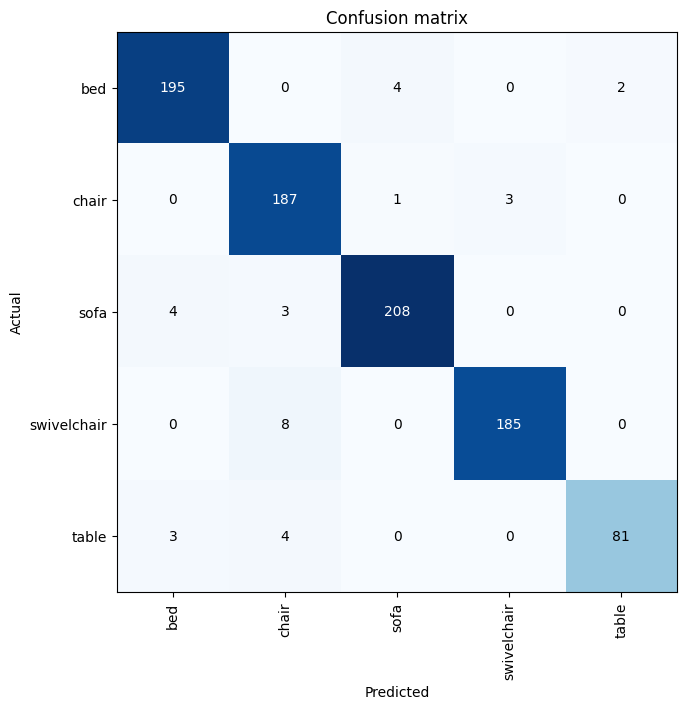

In [ ]:
interp.plot_confusion_matrix(figsize=(7, 7))

In [ ]:
cm = interp.confusion_matrix()

print(f"Error rate: {(cm.sum() - cm.trace()) / cm.sum():.2%}")

Error rate: 3.60%


### Confusion Matrix Interpretation

The ResNet34 model correctly classified 856 out of 888 validation images, achieving 96.40% accuracy and a 3.60% error rate.

The most noticeable confusion occurred between chairs and swivel chairs. The model incorrectly classified 8 swivel chairs as chairs and 3 chairs as swivel chairs.

These results suggest that the model sometimes struggles to distinguish furniture with similar visual features. However, it performed well overall across the five categories.

### Identify the most confused categories

Display the nine validation images with the highest losses to investigate the model's most significant prediction errors.

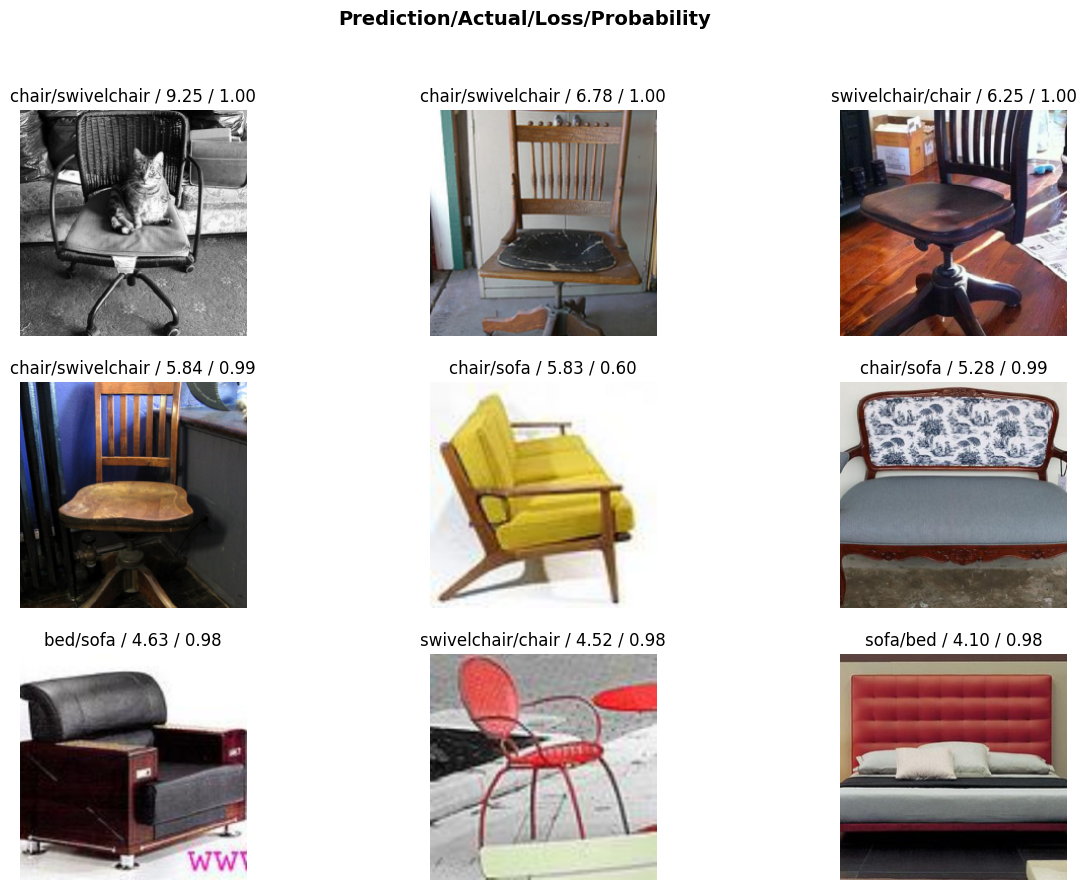

In [ ]:
interp.plot_top_losses(9, figsize=(15, 10))

### Error Analysis

The highest-loss images show that the model sometimes struggles to distinguish furniture with similar shapes, particularly chairs and swivel chairs.

Some mistakes also occurred between chairs and sofas, as well as beds and sofas. Unusual furniture designs and viewing angles may contribute to these errors.

Interestingly, the model made some incorrect predictions with very high confidence. This shows that a high predicted probability does not always mean the classification is correct.

## Prediction on an External Image

To further evaluate the model, I will test it on two chair photographs from outside the Kaggle dataset.

The first image comes from Wikimedia Commons, while the second is a photograph of a chair from my house that I uploaded to GitHub.

These tests allow me to examine how the trained model performs on images from different sources.

### External Test 1 — Wikimedia Commons

I selected a chair photograph from [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Chair_2020_P01.jpg), photographed by Fallaner (CC BY-SA 4.0).

I will use the trained ResNet34 model to predict the furniture category and examine its confidence score.

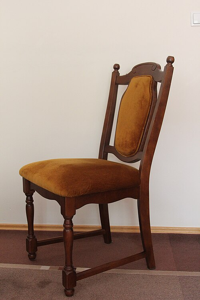

Actual category: chair
Predicted category: chair
Confidence: 99.99%


In [ ]:
external_url = "https://thumb.wikimedia.org/wikipedia/commons/thumb/0/04/Chair_2020_P01.jpg/500px-Chair_2020_P01.jpg"

external_image_path = Path("external_chair.jpg")

download_url(external_url, external_image_path, show_progress=False)

img = PILImage.create(external_image_path)
display(img.to_thumb(300))

prediction, pred_idx, probabilities = learn.predict(img)

print("Actual category: chair")
print("Predicted category:", prediction)
print(f"Confidence: {probabilities[pred_idx]:.2%}")

The model correctly classified the Wikimedia Commons image as a chair with 99.99% confidence.

### External Test 2 — My Own Chair

I also took a photograph of a chair from my house and uploaded it to my [GitHub repository](https://github.com/tphan356/household-object-classification/blob/main/dinner_chair.jpg).

Unlike the previous example, this image was taken in a real indoor environment and includes background objects.

I will use the same trained ResNet34 model to predict its category.

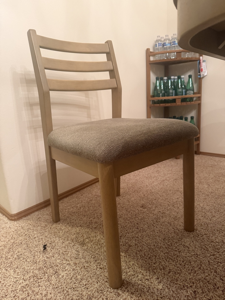

Actual category: chair
Predicted category: chair
Confidence: 99.74%


In [ ]:
external_url = "https://raw.githubusercontent.com/tphan356/household-object-classification/main/dinner_chair.jpg"

external_image_path = Path("external_chair.jpg")

download_url(external_url, external_image_path, show_progress=False)

img = PILImage.create(external_image_path)
display(img.to_thumb(300))

prediction, pred_idx, probabilities = learn.predict(img)

print("Actual category: chair")
print("Predicted category:", prediction)
print(f"Confidence: {probabilities[pred_idx]:.2%}")

The model correctly classified my chair photograph with **99.74% confidence**.

### External Image Prediction — Interpretation

The ResNet34 model correctly classified both external chair photographs, achieving **99.99% confidence** on the Wikimedia Commons image and **99.74% confidence** on my own photograph.

These results are encouraging because the model successfully recognized chair images from sources outside the Kaggle dataset.

However, high confidence does not guarantee that a prediction is correct. Additional external images, including other furniture categories, would be needed to evaluate the model's generalization more reliably.

## Conclusion

In this project, I used transfer learning with a pretrained ResNet34 model to classify five furniture categories.

After cleaning the dataset and removing duplicate images, I trained the model on 3,556 images and evaluated it on 888 validation images.

The model achieved 96.40% validation accuracy and a 3.60% error rate, correctly classifying 856 out of 888 validation images.

The main challenge was distinguishing visually similar furniture, particularly chairs and swivel chairs. However, the model successfully classified both external chair photographs.

Overall, this project demonstrated the effectiveness of transfer learning for multi-class image classification and highlighted the importance of dataset quality and error analysis.

For future work, I would like to improve the model using more diverse furniture images and additional external testing. My long-term goal is to extend the project to object detection and semantic mapping for intelligent home robotics.